## Pipeline Minimum Minggu 2: `02_pipeline_minimum_A2.ipynb`

**Lokasi:** Di dalam folder `Notebooks/` (`proyek-A2-icecube/Notebooks/02_pipeline_minimum_A2.ipynb`)  
**Fungsi:** Kode Python utama Minggu 2 (Gerbang G2) untuk memuat dan memvalidasi 10 musim data IceCube (`IC40`–`IC86_VII`, 1.134.450 *event*), membangun model latar belakang $B(\delta)$ dalam 40 bin $\sin\delta$, menghitung *Test Statistic* ($TS$) *Time-Integrated Unbinned Maximum Likelihood* ($\psi_{\max} = 5,0^\circ$) untuk kandidat blazar **TXS 0506+056** dan **PKS 1424+240**, menjalankan $M = 1000$ *pseudo-experiment* (`seed = 42`), serta melakukan verifikasi silang dua cara (*loop* manual vs komputasi vektor).

In [1]:
# ============================================================
# SEL 1: DATA LOADER & VALIDASI DATA ICECUBE (10 MUSIM)
# ============================================================
from pathlib import Path
import sys
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
RAW_FOLDER = PROJECT_ROOT / "dataverse_files" / "events"
PROCESSED_FOLDER = PROJECT_ROOT / "results" / "processed"
TABLE_FOLDER = PROJECT_ROOT / "results" / "tables"
LOG_FOLDER = PROJECT_ROOT / "results" / "logs"

SEASON_FILES = [
    "IC40_exp.csv", "IC59_exp.csv", "IC79_exp.csv",
    "IC86_I_exp.csv", "IC86_II_exp.csv", "IC86_III_exp.csv",
    "IC86_IV_exp.csv", "IC86_V_exp.csv", "IC86_VI_exp.csv",
    "IC86_VII_exp.csv",
]

COLUMNS = [
    "MJD", "log10_E_GeV", "AngErr_deg", "RA_deg",
    "Dec_deg", "Azimuth_deg", "Zenith_deg",
]


def load_one_season(file_path: Path) -> pd.DataFrame:
    """Membaca satu file event IceCube berformat whitespace-delimited."""
    if not file_path.is_file():
        raise FileNotFoundError(f"File tidak ditemukan: {file_path}")

    df = pd.read_csv(
        file_path, sep=r"\s+", comment="#", header=None,
        names=COLUMNS, engine="python"
    )
    if df.empty:
        raise ValueError(f"File kosong: {file_path.name}")

    df["Season"] = file_path.stem.replace("_exp", "")
    return df


def load_all_seasons(raw_folder: Path = RAW_FOLDER) -> pd.DataFrame:
    """Membaca sepuluh musim dan menggabungkannya menjadi satu DataFrame."""
    frames = []
    for filename in SEASON_FILES:
        df = load_one_season(raw_folder / filename)
        frames.append(df)
        print(f"[OK] {filename}: {len(df):,} event")
    return pd.concat(frames, ignore_index=True)


def transform_data(df: pd.DataFrame) -> pd.DataFrame:
    """Menambahkan sin_dec dan menormalisasi sudut periodik pada batas 360°."""
    data = df.copy()
    data.loc[np.isclose(data["RA_deg"], 360.0), "RA_deg"] = 0.0
    data.loc[np.isclose(data["Azimuth_deg"], 360.0), "Azimuth_deg"] = 0.0
    data["sin_dec"] = np.sin(np.deg2rad(data["Dec_deg"]))
    return data


def validate_data(df: pd.DataFrame) -> pd.DataFrame:
    """Memeriksa nilai kosong, non-finite, dan batas fisis tanpa menghapus baris."""
    required = COLUMNS + ["Season", "sin_dec"]
    missing_columns = [col for col in required if col not in df.columns]
    if missing_columns:
        raise ValueError(f"Kolom wajib tidak tersedia: {missing_columns}")

    print("\nNilai kosong per kolom:")
    print(df[required].isna().sum().to_string())

    nonfinite = {col: int((~np.isfinite(df[col])).sum()) for col in COLUMNS}
    print("\nNilai non-finite per kolom numerik:")
    print(pd.Series(nonfinite).to_string())

    checks = {
        "AngErr_nonpositive": df["AngErr_deg"] <= 0,
        "RA_out_of_range": (df["RA_deg"] < 0) | (df["RA_deg"] >= 360),
        "Dec_out_of_range": (df["Dec_deg"] < -90) | (df["Dec_deg"] > 90),
        "Azimuth_out_of_range": (df["Azimuth_deg"] < 0) | (df["Azimuth_deg"] >= 360),
        "Zenith_out_of_range": (df["Zenith_deg"] < 0) | (df["Zenith_deg"] > 180),
    }

    found = []
    for reason, mask in checks.items():
        mask = mask.fillna(True)
        if mask.any():
            part = df.loc[mask, COLUMNS + ["Season"]].copy()
            part.insert(0, "Anomaly", reason)
            found.append(part)

    anomalies = (
        pd.concat(found, ignore_index=True)
        if found else pd.DataFrame(columns=["Anomaly"] + COLUMNS + ["Season"])
    )

    invalid_numeric = ~np.isfinite(df[COLUMNS]).all(axis=1)
    if invalid_numeric.any():
        part = df.loc[invalid_numeric, COLUMNS + ["Season"]].copy()
        part.insert(0, "Anomaly", "Missing_or_nonfinite_numeric")
        anomalies = pd.concat([anomalies, part], ignore_index=True)

    print(f"\nJumlah baris-temuan validasi: {len(anomalies):,}")
    return anomalies


def create_season_summary(df: pd.DataFrame) -> pd.DataFrame:
    """Ringkasan jumlah event, rentang waktu, energi, dan AngErr per musim."""
    summary = (
        df.groupby("Season", sort=False)
        .agg(
            jumlah_event=("MJD", "size"),
            mjd_min=("MJD", "min"),
            mjd_max=("MJD", "max"),
            median_log10_E_GeV=("log10_E_GeV", "median"),
            median_AngErr_deg=("AngErr_deg", "median"),
            median_Dec_deg=("Dec_deg", "median"),
            median_RA_deg=("RA_deg", "median"),
        )
        .reset_index()
    )
    summary["median_energy_GeV"] = 10 ** summary["median_log10_E_GeV"]
    return summary


def create_sin_dec_distribution(df: pd.DataFrame, number_of_bins: int = 40) -> pd.DataFrame:
    """Distribusi event dalam 40 bin sin(Dec), sebagai bahan awal background."""
    values = df["sin_dec"].dropna()
    counts, edges = np.histogram(values, bins=number_of_bins, range=(-1, 1))
    return pd.DataFrame({
        "sin_dec_bin_left": edges[:-1],
        "sin_dec_bin_right": edges[1:],
        "jumlah_event": counts,
    })


def save_outputs(df, summary, anomalies, sin_dec_table) -> None:
    PROCESSED_FOLDER.mkdir(parents=True, exist_ok=True)
    TABLE_FOLDER.mkdir(parents=True, exist_ok=True)
    LOG_FOLDER.mkdir(parents=True, exist_ok=True)

    parquet_path = PROCESSED_FOLDER / "events_all_seasons.parquet"
    try:
        df.to_parquet(parquet_path, index=False)
        print(f"[SAVED] {parquet_path}")
    except (ImportError, ModuleNotFoundError):
        csv_path = PROCESSED_FOLDER / "events_all_seasons.csv.gz"
        df.to_csv(csv_path, index=False, compression="gzip")
        print(f"[SAVED] {csv_path}")

    summary.to_csv(TABLE_FOLDER / "ringkasan_per_musim.csv", index=False)
    sin_dec_table.to_csv(TABLE_FOLDER / "distribusi_sin_dec_40_bin.csv", index=False)
    anomalies.to_csv(LOG_FOLDER / "anomali_validasi_minggu2.csv", index=False)
    print(f"[SAVED] {TABLE_FOLDER / 'ringkasan_per_musim.csv'}")
    print(f"[SAVED] {TABLE_FOLDER / 'distribusi_sin_dec_40_bin.csv'}")
    print(f"[SAVED] {LOG_FOLDER / 'anomali_validasi_minggu2.csv'}")


def jalankan_data_loader() -> None:
    print("=" * 60)
    print("ICECUBE A2 - DATA LOADER MINGGU 2")
    print("=" * 60)
    raw = load_all_seasons(RAW_FOLDER)
    print(f"\nTotal event sebelum transformasi: {len(raw):,}")

    processed = transform_data(raw)
    anomalies = validate_data(processed)
    summary = create_season_summary(processed)
    sin_dec_table = create_sin_dec_distribution(processed, number_of_bins=40)

    save_outputs(processed, summary, anomalies, sin_dec_table)
    print("\nRingkasan per musim:")
    print(summary[["Season", "jumlah_event", "mjd_min", "mjd_max"]].to_string(index=False))
    print(f"\nData Loader selesai. Total event: {len(processed):,} | Musim: {processed['Season'].nunique()}")


jalankan_data_loader()

ICECUBE A2 - DATA LOADER MINGGU 2
[OK] IC40_exp.csv: 36,900 event
[OK] IC59_exp.csv: 107,011 event
[OK] IC79_exp.csv: 93,133 event
[OK] IC86_I_exp.csv: 136,244 event
[OK] IC86_II_exp.csv: 112,858 event
[OK] IC86_III_exp.csv: 122,541 event
[OK] IC86_IV_exp.csv: 127,045 event
[OK] IC86_V_exp.csv: 129,311 event
[OK] IC86_VI_exp.csv: 123,657 event
[OK] IC86_VII_exp.csv: 145,750 event

Total event sebelum transformasi: 1,134,450

Nilai kosong per kolom:
MJD            0
log10_E_GeV    0
AngErr_deg     0
RA_deg         0
Dec_deg        0
Azimuth_deg    0
Zenith_deg     0
Season         0
sin_dec        0

Nilai non-finite per kolom numerik:
MJD            0
log10_E_GeV    0
AngErr_deg     0
RA_deg         0
Dec_deg        0
Azimuth_deg    0
Zenith_deg     0

Jumlah baris-temuan validasi: 0
[SAVED] c:\Users\COMPUTER\Downloads\proyek-A2-icecube-main (1)\proyek-A2-icecube-main\results\processed\events_all_seasons.parquet
[SAVED] c:\Users\COMPUTER\Downloads\proyek-A2-icecube-main (1)\proyek-A2-i

### Bagian 2: Perhitungan Likelihood Spasial, Pseudo-Experiment ($M = 1000$), dan Cek Dua Cara (Gerbang G2)

Dimuat 1,134,450 event dari 10 musim; B(dec) = gabungan, M = 1000, seed = 42, radius = 5.0 derajat
TXS 0506+056: TS = 1.660, ns_hat = 15.15, Nd = 3725, p_pra = 0.07892, Z = 1.41 sigma (satu sisi), TS=0 pada pseudo: 59%
PKS 1424+240: TS = 8.182, ns_hat = 36.17, Nd = 2555, p_pra = 0.001998, Z = 2.88 sigma (satu sisi), TS=0 pada pseudo: 57%
Dua sumber (pasca-trial): TS_maks = 8.182 (PKS 1424+240), p = 0.002997, Z = 2.75 sigma, trial factor efektif = 1.50
Cek dua cara TXS 0506+056: manual = 0.4894147430, vektor = 0.4894147430, cocok = True
Cek dua cara PKS 1424+240: manual = 1.2044401680, vektor = 1.2044401680, cocok = True


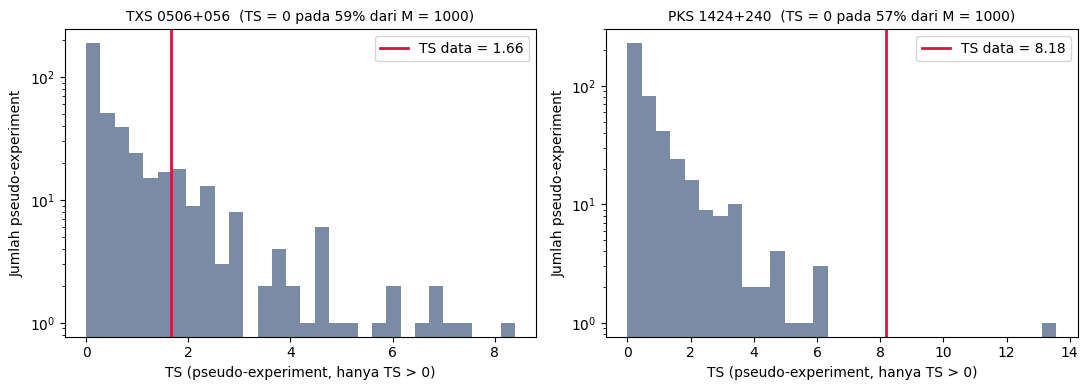

Tersimpan di Results/Tables/ dan Results/Figures/


In [2]:
# ============================================================
# SEL 2: PIPELINE STATISTIK MINIMUM A2 & VERIFIKASI GERBANG 2
# ============================================================
import argparse
import hashlib
import json
import math
import sys
import tempfile
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy.optimize import minimize_scalar

RAIZ = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "SRC"))
import statistik as st  # noqa: E402

NAMA_KOLOM = ["MJD", "log10_E_GeV", "AngErr_deg", "RA_deg", "Dec_deg",
              "Azimuth_deg", "Zenith_deg"]
URUTAN_MUSIM = ["IC40", "IC59", "IC79", "IC86_I", "IC86_II", "IC86_III",
                "IC86_IV", "IC86_V", "IC86_VI", "IC86_VII"]

SUMBER = {
    "TXS 0506+056": (77.358185, 5.693148),
    "PKS 1424+240": (216.751632, 23.800010),
}

R50_KE_SIGMA = 1.1774


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for blok in iter(lambda: f.read(1 << 20), b""):
            h.update(blok)
    return h.hexdigest()


def muat_data(folder):
    """Baca semua *_exp.csv, beri label Season, seragamkan nama kolom."""
    folder = Path(folder)
    berkas = {p.name.replace("_exp.csv", ""): p for p in folder.glob("*_exp.csv")}
    if not berkas:
        raise FileNotFoundError(f"Tidak ada *_exp.csv di {folder}")
    musim = [m for m in URUTAN_MUSIM if m in berkas] + \
            sorted(m for m in berkas if m not in URUTAN_MUSIM)
    bagian, checksum = [], {}
    for m in musim:
        d = pd.read_csv(berkas[m], sep=r"\s+", comment="#", header=None,
                        names=NAMA_KOLOM)
        d["season"] = m
        bagian.append(d)
        checksum[berkas[m].name] = sha256(berkas[m])
    df = pd.concat(bagian, ignore_index=True)
    df = df.rename(columns={"MJD": "mjd", "log10_E_GeV": "log10E",
                            "AngErr_deg": "ang_err", "RA_deg": "ra",
                            "Dec_deg": "dec", "Azimuth_deg": "azi",
                            "Zenith_deg": "zen"})
    df["ra"] = df["ra"] % 360.0
    return df, musim, checksum


def bangun_B_event(df, mode="gabungan", nbin=40):
    """Mengembalikan B (per steradian) untuk tiap event."""
    dec = df["dec"].values
    if mode == "gabungan":
        return st.bangun_bkg_pdf(dec, nbin)(dec)
    B = np.empty(len(df))
    for m in df["season"].unique():
        idx = (df["season"] == m).values
        B[idx] = st.bangun_bkg_pdf(dec[idx], nbin)(dec[idx])
    return B


class SumberTS:
    """Statistik unbinned maximum likelihood spasial untuk satu sumber."""

    def __init__(self, nama, ra, dec, df, B_event, N, radius, faktor_sigma):
        self.nama, self.ra0, self.dec0 = nama, ra, dec
        self.radius, self.N = radius, N
        pita = np.abs(df["dec"].values - dec) < radius
        self.ra_obs = df["ra"].values[pita]
        self.dec = df["dec"].values[pita]
        self.sig = np.radians(df["ang_err"].values[pita] * faktor_sigma)
        self.B = B_event[pita]
        self.n_pita = int(pita.sum())
        d, d0 = np.radians(self.dec), np.radians(dec)
        self._a = np.sin(d) * np.sin(d0)
        self._b = np.cos(d) * np.cos(d0)
        self._cos_r = np.cos(np.radians(radius))

    def ts(self, ra):
        """(TS, ns_hat, Nd) untuk satu set RA."""
        c = self._a + self._b * np.cos(np.radians(ra - self.ra0))
        dekat = c > self._cos_r
        Nd = int(dekat.sum())
        if Nd == 0:
            return 0.0, 0.0, 0
        psi = np.arccos(np.clip(c[dekat], -1, 1))
        s2 = self.sig[dekat] ** 2
        rasio = np.exp(-psi ** 2 / (2 * s2)) / (2 * np.pi * s2) / self.B[dekat]
        N = self.N
        if (rasio.sum() - N) <= 0:
            return 0.0, 0.0, Nd

        def dlogL(ns):
            x = ns / N
            return np.sum(np.log1p(x * (rasio - 1.0))) + (N - Nd) * np.log1p(-x)

        h = minimize_scalar(lambda n: -dlogL(n), bounds=(0.0, float(Nd)),
                            method="bounded", options={"xatol": 1e-6})
        ts = 2.0 * dlogL(h.x)
        if ts < 1e-9:
            return 0.0, 0.0, Nd
        return float(ts), float(h.x), Nd

    def cek_manual(self, ns):
        """ln L(ns) - ln L(0) dengan loop skalar (math) untuk validasi Gerbang G2."""
        N, tot, Nd = self.N, 0.0, 0
        for i in range(self.n_pita):
            d1, d2 = math.radians(self.dec[i]), math.radians(self.dec0)
            c = (math.sin(d1) * math.sin(d2) + math.cos(d1) * math.cos(d2)
                 * math.cos(math.radians(self.ra_obs[i] - self.ra0)))
            psi = math.acos(max(-1.0, min(1.0, c)))
            if math.degrees(psi) < self.radius:
                Nd += 1
                S = math.exp(-psi ** 2 / (2 * self.sig[i] ** 2)) / \
                    (2 * math.pi * self.sig[i] ** 2)
                tot += math.log(1 + (ns / N) * (S / self.B[i] - 1))
        tot += (N - Nd) * math.log(1 - ns / N)
        return tot, Nd

    def dlogL_vektor(self, ns):
        c = self._a + self._b * np.cos(np.radians(self.ra_obs - self.ra0))
        dekat = c > self._cos_r
        psi = np.arccos(np.clip(c[dekat], -1, 1))
        s2 = self.sig[dekat] ** 2
        rasio = np.exp(-psi ** 2 / (2 * s2)) / (2 * np.pi * s2) / self.B[dekat]
        x = ns / self.N
        Nd = int(dekat.sum())
        return float(np.sum(np.log1p(x * (rasio - 1.0))) + (self.N - Nd) * np.log1p(-x)), Nd


def jalankan(df, musim, checksum, M, seed, radius, nbin, bkg, faktor_sigma, sumber=SUMBER):
    N = len(df)
    B_event = bangun_B_event(df, bkg, nbin)
    S = [SumberTS(n, ra, dec, df, B_event, N, radius, faktor_sigma)
         for n, (ra, dec) in sumber.items()]

    obs = [s.ts(s.ra_obs) for s in S]

    anak = np.random.SeedSequence(seed).spawn(M)
    ts_bkg = np.zeros((M, len(S)))
    for k in range(M):
        rng = np.random.default_rng(anak[k])
        for j, s in enumerate(S):
            ts_bkg[k, j] = s.ts(rng.uniform(0.0, 360.0, size=s.n_pita))[0]
    ts_maks_bkg = ts_bkg.max(axis=1)

    hasil = {"sumber": {}}
    ts_obs_maks = max(o[0] for o in obs)
    p_pasca, k_pasca, _ = st.p_value(ts_obs_maks, ts_maks_bkg)
    for j, s in enumerate(S):
        ts_o, ns_o, Nd_o = obs[j]
        p, kk, MM = st.p_value(ts_o, ts_bkg[:, j])
        hasil["sumber"][s.nama] = {
            "ra_deg": s.ra0, "dec_deg": s.dec0, "N_dekat_radius": Nd_o,
            "TS_obs": ts_o, "ns_hat": ns_o,
            "k": kk, "M": MM, "p_pra_trial": p,
            "p_pra_trial_batas_atas_jika_k0": (1.0 / MM) if kk == 0 else None,
            "sigma_pra_trial_satu_sisi": st.sigma_satu_sisi(p),
            "frac_TS_nol_pseudo": float(np.mean(ts_bkg[:, j] == 0.0)),
        }
    hasil["dua_sumber"] = {
        "TS_maks_obs": ts_obs_maks,
        "sumber_pemilik_TS_maks": S[int(np.argmax([o[0] for o in obs]))].nama,
        "k": k_pasca, "M": M, "p_pasca_trial": p_pasca,
        "sigma_pasca_trial_satu_sisi": st.sigma_satu_sisi(p_pasca),
        "trial_factor_efektif": p_pasca / min(h["p_pra_trial"]
                                              for h in hasil["sumber"].values()),
    }

    cek = {}
    for s in S:
        ns_uji = 5.0
        manual, Nd_m = s.cek_manual(ns_uji)
        vek, Nd_v = s.dlogL_vektor(ns_uji)
        cek[s.nama] = {"ns_uji": ns_uji, "lnL_rasio_manual_loop": manual,
                       "lnL_rasio_vektor": vek, "selisih": abs(manual - vek),
                       "Nd_manual": Nd_m, "Nd_vektor": Nd_v,
                       "cocok": bool(abs(manual - vek) < 1e-8 and Nd_m == Nd_v)}
    hasil["cek_dua_cara"] = cek

    hasil["metadata"] = {
        "waktu_jalan": datetime.now().isoformat(timespec="seconds"),
        "seed_dasar": seed,
        "skema_seed": "SeedSequence(seed).spawn(M): seed berbeda tiap pseudo-experiment",
        "M": M, "radius_deg": radius, "nbin_sin_dec": nbin, "B_delta": bkg,
        "faktor_sigma_terhadap_AngErr": faktor_sigma,
        "N_event_total": N, "musim": musim,
        "event_per_musim": df["season"].value_counts().reindex(musim).to_dict(),
        "versi": {"python": sys.version.split()[0], "numpy": np.__version__,
                  "scipy": scipy.__version__, "pandas": pd.__version__},
        "checksum_sha256": checksum,
        "catatan": "Koordinat sumber dari NED (diakses 20 November 2026). AngErr dipakai langsung sebagai sigma (Gerbang 0 no. 3)."
    }
    return hasil, ts_bkg, ts_maks_bkg


def simpan(hasil, ts_bkg, ts_maks_bkg, nama_sumber):
    tab = RAIZ / "Results" / "Tables"
    fig = RAIZ / "Results" / "Figures"
    tab.mkdir(parents=True, exist_ok=True)
    fig.mkdir(parents=True, exist_ok=True)
    with open(tab / "hasil_minimum_A2.json", "w", encoding="utf-8") as f:
        json.dump(hasil, f, indent=2, ensure_ascii=False, default=float)

    baris = []
    for n, h in hasil["sumber"].items():
        baris.append({
            "sumber": n, "TS_obs": round(h["TS_obs"], 3),
            "ns_hat": round(h["ns_hat"], 3), "N_dekat": h["N_dekat_radius"],
            "k": h["k"], "M": h["M"],
            "p_pra_trial": (f"< {1/h['M']:.3g}" if h["k"] == 0 else f"{h['p_pra_trial']:.4g}"),
            "sigma_pra_trial (satu sisi)": round(h["sigma_pra_trial_satu_sisi"], 2),
        })
    d = hasil["dua_sumber"]
    baris.append({
        "sumber": "dua sumber (TS maks)", "TS_obs": round(d["TS_maks_obs"], 3),
        "ns_hat": "", "N_dekat": "", "k": d["k"], "M": d["M"],
        "p_pra_trial": (f"< {1/d['M']:.3g} (pasca-trial)" if d["k"] == 0
                        else f"{d['p_pasca_trial']:.4g} (pasca-trial)"),
        "sigma_pra_trial (satu sisi)": round(d["sigma_pasca_trial_satu_sisi"], 2),
    })
    pd.DataFrame(baris).to_csv(tab / "tabel_TS_sumber.csv", index=False)

    import matplotlib.pyplot as plt
    fg, ax = plt.subplots(1, len(nama_sumber), figsize=(5.5 * len(nama_sumber), 4), squeeze=False)
    for j, n in enumerate(nama_sumber):
        a = ax[0, j]
        a.hist(ts_bkg[:, j][ts_bkg[:, j] > 0], bins=30, color="#7a8ba6")
        a.set_yscale("log")
        a.axvline(hasil["sumber"][n]["TS_obs"], color="crimson", lw=2,
                  label=f"TS data = {hasil['sumber'][n]['TS_obs']:.2f}")
        a.set_xlabel("TS (pseudo-experiment, hanya TS > 0)")
        a.set_ylabel("Jumlah pseudo-experiment")
        z = hasil["sumber"][n]["frac_TS_nol_pseudo"]
        a.set_title(f"{n}  (TS = 0 pada {100*z:.0f}% dari M = {len(ts_bkg)})", fontsize=10)
        a.legend()
    fg.tight_layout()
    fg.savefig(fig / "distribusi_TS_pseudo.png", dpi=200)
    plt.show()


def jalankan_statistik():
    df, musim, cks = muat_data(RAIZ / "dataverse_files" / "events")
    print(f"Dimuat {len(df):,} event dari {len(musim)} musim; B(dec) = gabungan, "
          f"M = 1000, seed = 42, radius = 5.0 derajat")
    hasil, tsb, tsm = jalankan(df, musim, cks, M=1000, seed=42, radius=5.0,
                               nbin=40, bkg="gabungan", faktor_sigma=1.0)
    for n, h in hasil["sumber"].items():
        pstr = f"< {1/h['M']:.3g}" if h["k"] == 0 else f"{h['p_pra_trial']:.4g}"
        print(f"{n}: TS = {h['TS_obs']:.3f}, ns_hat = {h['ns_hat']:.2f}, "
              f"Nd = {h['N_dekat_radius']}, p_pra = {pstr}, "
              f"Z = {h['sigma_pra_trial_satu_sisi']:.2f} sigma (satu sisi), "
              f"TS=0 pada pseudo: {100*h['frac_TS_nol_pseudo']:.0f}%")
    d = hasil["dua_sumber"]
    print(f"Dua sumber (pasca-trial): TS_maks = {d['TS_maks_obs']:.3f} "
          f"({d['sumber_pemilik_TS_maks']}), p = {d['p_pasca_trial']:.4g}, "
          f"Z = {d['sigma_pasca_trial_satu_sisi']:.2f} sigma, "
          f"trial factor efektif = {d['trial_factor_efektif']:.2f}")
    for n, c in hasil["cek_dua_cara"].items():
        print(f"Cek dua cara {n}: manual = {c['lnL_rasio_manual_loop']:.10f}, "
              f"vektor = {c['lnL_rasio_vektor']:.10f}, cocok = {c['cocok']}")
    simpan(hasil, tsb, tsm, list(SUMBER))
    print("Tersimpan di Results/Tables/ dan Results/Figures/")


jalankan_statistik()